# A. Ritme Harian Kapanewon di DIY

**Data:** `presence_kapanewon_hourly.csv` (JogjaPulse)
**Penanggung jawab:** Anggota A

## Pertanyaan riset

1. Jam berapa puncak kehadiran di tiap kapanewon, dan bagaimana bedanya antar kabupaten/kota?
2. Seberapa beda pola hari kerja, Sabtu, dan Minggu?
3. Kapanewon mana yang ramai siang tapi sepi malam, dan mana yang tetap ramai sampai malam?

## Setup

In [1]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().parent / "src"))  # supaya `import ritme` jalan tanpa pip install

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ritme import io, prep, style

style.apply()

## Metode

Data mentah tidak bisa langsung dibandingkan. Ada tiga masalah (README dataset bagian 5 dan 6) dan cara kami menanganinya:

| Masalah | Penanganan di notebook ini |
|---|---|
| Jumlah perangkat teramati turun drastis (≈87 ribu/hari Des → ≈9 ribu/hari Apr), dengan lompatan 1 Jan & 16 Feb | Normalisasi per kapanewon per hari: tiap jam dibagi rata-rata 24 jam kapanewon itu pada hari itu, sehingga yang dibandingkan bentuk profilnya. Hari kerja, Sabtu, dan Minggu memakai 1 Des 2021 sampai 28 Feb 2022, saat sampel paling besar dan stabil. Perbandingan hari libur memakai seluruh periode (lihat bagian 4). |
| Jam dengan < 5 perangkat dihapus (baris hilang ≠ nol). Jam malam di pedesaan paling sering hilang. Kalau dibiarkan, rata-rata malam jadi terlalu tinggi. | Baris hilang diisi 2,5 (titik tengah 0 sampai 4). Proporsi jam yang diisi kami laporkan per kapanewon, dan kami uji ulang dengan isian 0 dan 4,9. |
| Hari libur dan anomali data mengganggu pola hari biasa | Hari libur nasional dan cuti bersama dari kalender resmi jadi kategori sendiri, tidak dicampur dengan hari kerja atau akhir pekan. Tanggal anomali data dibuang dari semua analisis: 1 Jan dan 16 Feb (lompatan turun jumlah perangkat) serta 8 Mar (anomali satu hari). Cuti bersama 24 Des 2021 sudah dihapus pemerintah, jadi tanggal itu dihitung sebagai hari kerja biasa. |
| Beberapa jam di pagi hari datanya hampir kosong di seluruh DIY sekaligus, tanda gangguan pengiriman data | Jam siang (07-21) yang total ping seluruh DIY-nya di bawah 40% median jam yang sama dalam ±7 hari kami anggap kosong. Kami hanya menutup jam itu; jam lain di hari yang sama tetap dipakai. Hasil dengan dan tanpa penutupan ini ada di bagian 6. |
| Kapanewon bukan pengamatan yang saling bebas, karena semuanya berbagi hari yang sama | Ketidakpastian dihitung per hari dengan bootstrap: hari diambil ulang secara acak 2.000 kali, lalu dilaporkan interval kepercayaan 95%. Selisih disebut kuat hanya kalau intervalnya tidak melewati nol. |

Indeks = `n_maids` jam itu ÷ rata-rata `n_maids` 24 jam (kapanewon & hari yang sama). Indeks 1,3 berarti 30% di atas rata-rata hariannya.
Tipe hari: hari kerja (Senin-Jumat), Sabtu, Minggu, dan hari libur.

In [2]:
PERIODE_UTAMA = ("2021-12-01", "2022-02-28")
PERIODE_PENUH = ("2021-12-01", "2022-04-30")
ANOMALI_DATA = pd.to_datetime(["2022-01-01", "2022-02-16", "2022-03-08"])  # README dataset bagian 6

# Sementara, sampai kalender bersama dari anggota C tersedia.
SETKAB_2021 = "https://setkab.go.id/inilah-perubahan-hari-libur-nasional-dan-cuti-bersama-tahun-2021/"
SETKAB_2022 = "https://setkab.go.id/inilah-skb-3-menteri-perubahan-hari-libur-nasional-dan-cuti-bersama-tahun-2022/"
HARI_LIBUR = pd.DataFrame(
    [
        ("2021-12-25", "Natal", SETKAB_2021),
        ("2022-01-01", "Tahun Baru", SETKAB_2022),
        ("2022-02-01", "Imlek", SETKAB_2022),
        ("2022-02-28", "Isra Mikraj", SETKAB_2022),
        ("2022-03-03", "Nyepi", SETKAB_2022),
        ("2022-04-15", "Wafat Isa Almasih", SETKAB_2022),
        ("2022-04-29", "Cuti bersama Idulfitri", SETKAB_2022),
    ],
    columns=["tanggal", "nama", "sumber"],
).assign(tanggal=lambda d: pd.to_datetime(d["tanggal"]))
TANGGAL_LIBUR = HARI_LIBUR["tanggal"]
ISIAN_TERSUPRESI = 2.5
JAM_SIANG = list(range(8, 18))   # 08:00-17:59
JAM_MALAM = list(range(0, 6))    # 00:00-05:59
TIPE_HARI = ["Hari kerja", "Sabtu", "Minggu"]
JENDELA_PEMBANDING_HARI = 7
AMBANG_JAM_BOLONG = 0.4
JAM_CEK_BOLONG = range(7, 22)
N_BOOT = 2000

hourly = io.load_presence_hourly()
lookup = io.kapanewon_lookup()
print(hourly.shape, hourly.date.min().date(), "s/d", hourly.date.max().date())

(230418, 8) 2021-12-01 s/d 2022-04-30


In [3]:
def cari_jam_bolong(hourly):
    """Jam siang yang total ping seluruh DIY-nya < AMBANG_JAM_BOLONG × median jam yang sama dalam ±7 hari."""
    ping = hourly.groupby(["date", "hour"])["n_pings"].sum().unstack("hour")
    acuan = ping.rolling(15, center=True, min_periods=5).median()
    relatif = (ping / acuan).stack().rename("ping_relatif")
    bolong = relatif[(relatif < AMBANG_JAM_BOLONG) & relatif.index.get_level_values("hour").isin(JAM_CEK_BOLONG)]
    return bolong[~bolong.index.get_level_values("date").isin(ANOMALI_DATA)]


JAM_BOLONG = cari_jam_bolong(hourly)
JAM_BOLONG.round(2).reset_index().assign(hari=lambda d: d["date"].dt.day_name())

,date,hour,ping_relatif,hari
0,2022-01-22,10,0.35,Saturday
1,2022-01-27,9,0.34,Thursday
2,2022-02-04,8,0.08,Friday
3,2022-02-05,10,0.16,Saturday


In [4]:
def hitung_indeks(hourly, start, end, isian=ISIAN_TERSUPRESI, tutup_jam_bolong=True):
    """Grid lengkap kapanewon × hari × jam, isi jam tersupresi, normalisasi per kapanewon-hari.

    Mengembalikan (tabel indeks per baris, proporsi jam terisi per kapanewon).
    """
    d = hourly[hourly.date.between(start, end) & ~hourly.date.isin(ANOMALI_DATA)]
    grid = pd.MultiIndex.from_product(
        [lookup.kapanewon_code, sorted(d.date.unique()), range(24)],
        names=["kapanewon_code", "date", "hour"],
    )
    n = d.set_index(["kapanewon_code", "date", "hour"])["n_maids"].reindex(grid)
    terisi = n.isna().groupby(level="kapanewon_code").mean().rename("prop_jam_terisi")
    n = n.fillna(isian)
    if tutup_jam_bolong:
        tanggal_jam = pd.MultiIndex.from_arrays([n.index.get_level_values("date"), n.index.get_level_values("hour")])
        n = n.mask(tanggal_jam.isin(JAM_BOLONG.index))
    indeks = n / n.groupby(level=["kapanewon_code", "date"]).transform("mean")
    tabel = indeks.rename("indeks").reset_index().pipe(prep.add_calendar_columns)
    tabel["tipe_hari"] = np.select(
        [tabel.date.isin(TANGGAL_LIBUR), tabel.weekday < 5, tabel.weekday == 5],
        ["Hari libur", "Hari kerja", "Sabtu"],
        "Minggu",
    )
    return tabel, terisi


def profil(tabel):
    """Rata-rata indeks per kapanewon × tipe hari × jam (kolom = jam 0-23)."""
    return tabel.groupby(["kapanewon_code", "tipe_hari", "hour"])["indeks"].mean().unstack("hour")


def rasio_siang_malam(prof_hari_kerja):
    return (prof_hari_kerja[JAM_SIANG].mean(axis=1) / prof_hari_kerja[JAM_MALAM].mean(axis=1)).rename("rasio_siang_malam")


def harian_per_jam(tabel, tanggal):
    """Matriks hari × jam: rata-rata indeks semua kapanewon dalam `tabel` pada tiap tanggal."""
    return tabel[tabel["date"].isin(tanggal)].groupby(["date", "hour"])["indeks"].mean().unstack("hour")


def pita_bootstrap(harian, seed=0):
    """Rata-rata per jam dan interval kepercayaan 95% dari bootstrap atas hari."""
    m = harian.to_numpy()
    ambil = np.random.default_rng(seed).integers(0, len(m), size=(N_BOOT, len(m)))
    rata_boot = np.nanmean(m[ambil], axis=1)
    return np.nanmean(m, axis=0), np.percentile(rata_boot, 2.5, axis=0), np.percentile(rata_boot, 97.5, axis=0)


def ci_selisih(a, b, seed=0):
    """Selisih rata-rata b − a dengan interval kepercayaan 95% (bootstrap, a dan b diambil ulang terpisah)."""
    a, b = np.asarray(a), np.asarray(b)
    rng = np.random.default_rng(seed)
    boot = rng.choice(b, (N_BOOT, len(b))).mean(axis=1) - rng.choice(a, (N_BOOT, len(a))).mean(axis=1)
    bawah, atas = np.percentile(boot, [2.5, 97.5])
    return {"selisih": round(b.mean() - a.mean(), 3), "ci_bawah": round(bawah, 3), "ci_atas": round(atas, 3),
            "n_hari": len(b), "kuat": bool(bawah > 0 or atas < 0)}


tabel, terisi = hitung_indeks(hourly, *PERIODE_UTAMA)
prof = profil(tabel)
prof_kerja = prof.xs("Hari kerja", level="tipe_hari")
print("Jumlah hari per tipe:", tabel.drop_duplicates("date")["tipe_hari"].value_counts().to_dict())
terisi.to_frame().join(lookup.set_index("kapanewon_code")).groupby("kab_kota")["prop_jam_terisi"].agg(["mean", "max"]).round(3)

Jumlah hari per tipe: {'Hari kerja': 61, 'Minggu': 13, 'Sabtu': 11, 'Hari libur': 3}


,mean,max
kab_kota,,
BANTUL,0.022,0.111
GUNUNGKIDUL,0.222,0.664
KULON PROGO,0.042,0.135
SLEMAN,0.004,0.026
YOGYAKARTA,0.048,0.323


Gunungkidul paling banyak jam yang tersupresi (rata-rata 22%, maksimal 66% di Girisubo). Kapanewon dengan lebih dari 20% jam terisi kami tandai `*`, dan hasilnya kurang andal.

## 1. Profil 24 jam per kabupaten/kota

Rata-rata indeks semua kapanewon dalam kabupaten/kota, dipisah per tipe hari.

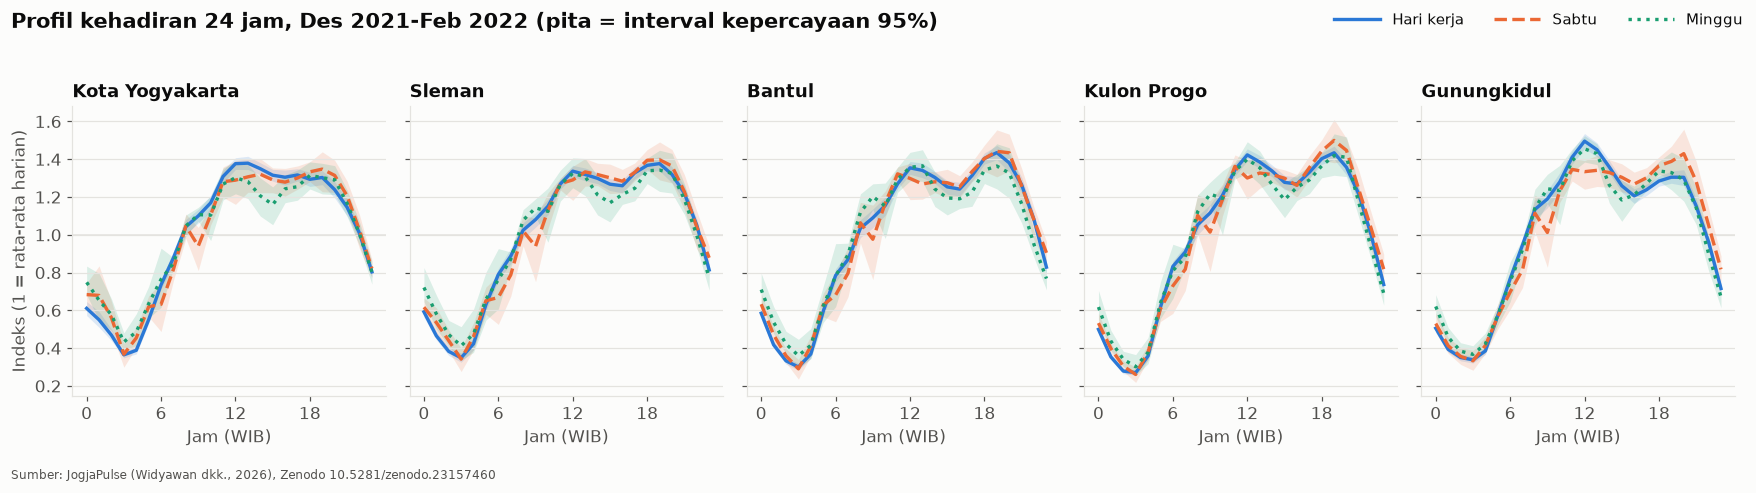

In [5]:
prof_kab = (
    prof.reset_index()
    .merge(lookup, on="kapanewon_code")
    .groupby(["kab_kota", "tipe_hari"])[list(range(24))].mean()
)
WARNA_HARI = dict(zip(TIPE_HARI, style.CATEGORICAL[:3]))
GARIS_HARI = {"Hari kerja": "-", "Sabtu": "--", "Minggu": ":"}  # pembeda selain warna
KAB_MAP = lookup.set_index("kapanewon_code")["kab_kota"]
tabel_kab = tabel.assign(kab_kota=tabel["kapanewon_code"].map(KAB_MAP))
tipe_per_tanggal = tabel.drop_duplicates("date").set_index("date")["tipe_hari"]

fig, axes = plt.subplots(1, 5, figsize=(16, 4.2), sharey=True)
for ax, kab in zip(axes, style.KAB_ORDER):
    for tipe in TIPE_HARI:
        harian = harian_per_jam(tabel_kab[tabel_kab["kab_kota"] == kab], tipe_per_tanggal.index[tipe_per_tanggal == tipe])
        rata, bawah, atas = pita_bootstrap(harian)
        ax.fill_between(range(24), bawah, atas, color=WARNA_HARI[tipe], alpha=0.15, linewidth=0)
        ax.plot(range(24), rata, color=WARNA_HARI[tipe], linestyle=GARIS_HARI[tipe], linewidth=2.2, label=tipe)
    ax.axhline(1, color=style.GRID, linewidth=1, zorder=0)
    ax.set_title(style.KAB_LABELS[kab], fontsize=12)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Jam (WIB)")
axes[0].set_ylabel("Indeks (1 = rata-rata harian)")
fig.suptitle("Profil kehadiran 24 jam, Des 2021-Feb 2022 (pita = interval kepercayaan 95%)", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, fontsize=10, handlelength=3)
fig.tight_layout(rect=(0, 0, 1, 0.95))
style.add_source(fig)
style.save(fig, "A1_profil_24jam_kabupaten")
plt.show()

Garis Sabtu masih turun sedikit pada pukul 09. Sebagian besar berasal dari 22 Januari, saat ping seluruh DIY pukul 09 hanya 41% dari biasanya, sedikit di atas ambang 40% yang kami tetapkan sejak awal. Kami tidak mengubah ambang setelah melihat hasil. Pita interval kepercayaan Sabtu di jam itu juga lebar.

In [6]:
ringkas = pd.DataFrame({
    "jam_terendah": prof_kab.xs("Hari kerja", level="tipe_hari").idxmin(axis=1),
    "indeks_terendah": prof_kab.xs("Hari kerja", level="tipe_hari").min(axis=1).round(2),
    "jam_puncak": prof_kab.xs("Hari kerja", level="tipe_hari").idxmax(axis=1),
    "indeks_puncak": prof_kab.xs("Hari kerja", level="tipe_hari").max(axis=1).round(2),
}).loc[style.KAB_ORDER]
ringkas

,jam_terendah,indeks_terendah,jam_puncak,indeks_puncak
kab_kota,,,,
YOGYAKARTA,3,0.36,13,1.38
SLEMAN,3,0.35,19,1.38
BANTUL,3,0.30,19,1.44
KULON PROGO,3,0.27,19,1.43
GUNUNGKIDUL,3,0.34,12,1.50


## 2. Jam puncak tiap kapanewon (hari kerja)

Tiap baris heatmap = satu kapanewon, diurutkan dari jam puncak paling awal ke paling akhir.

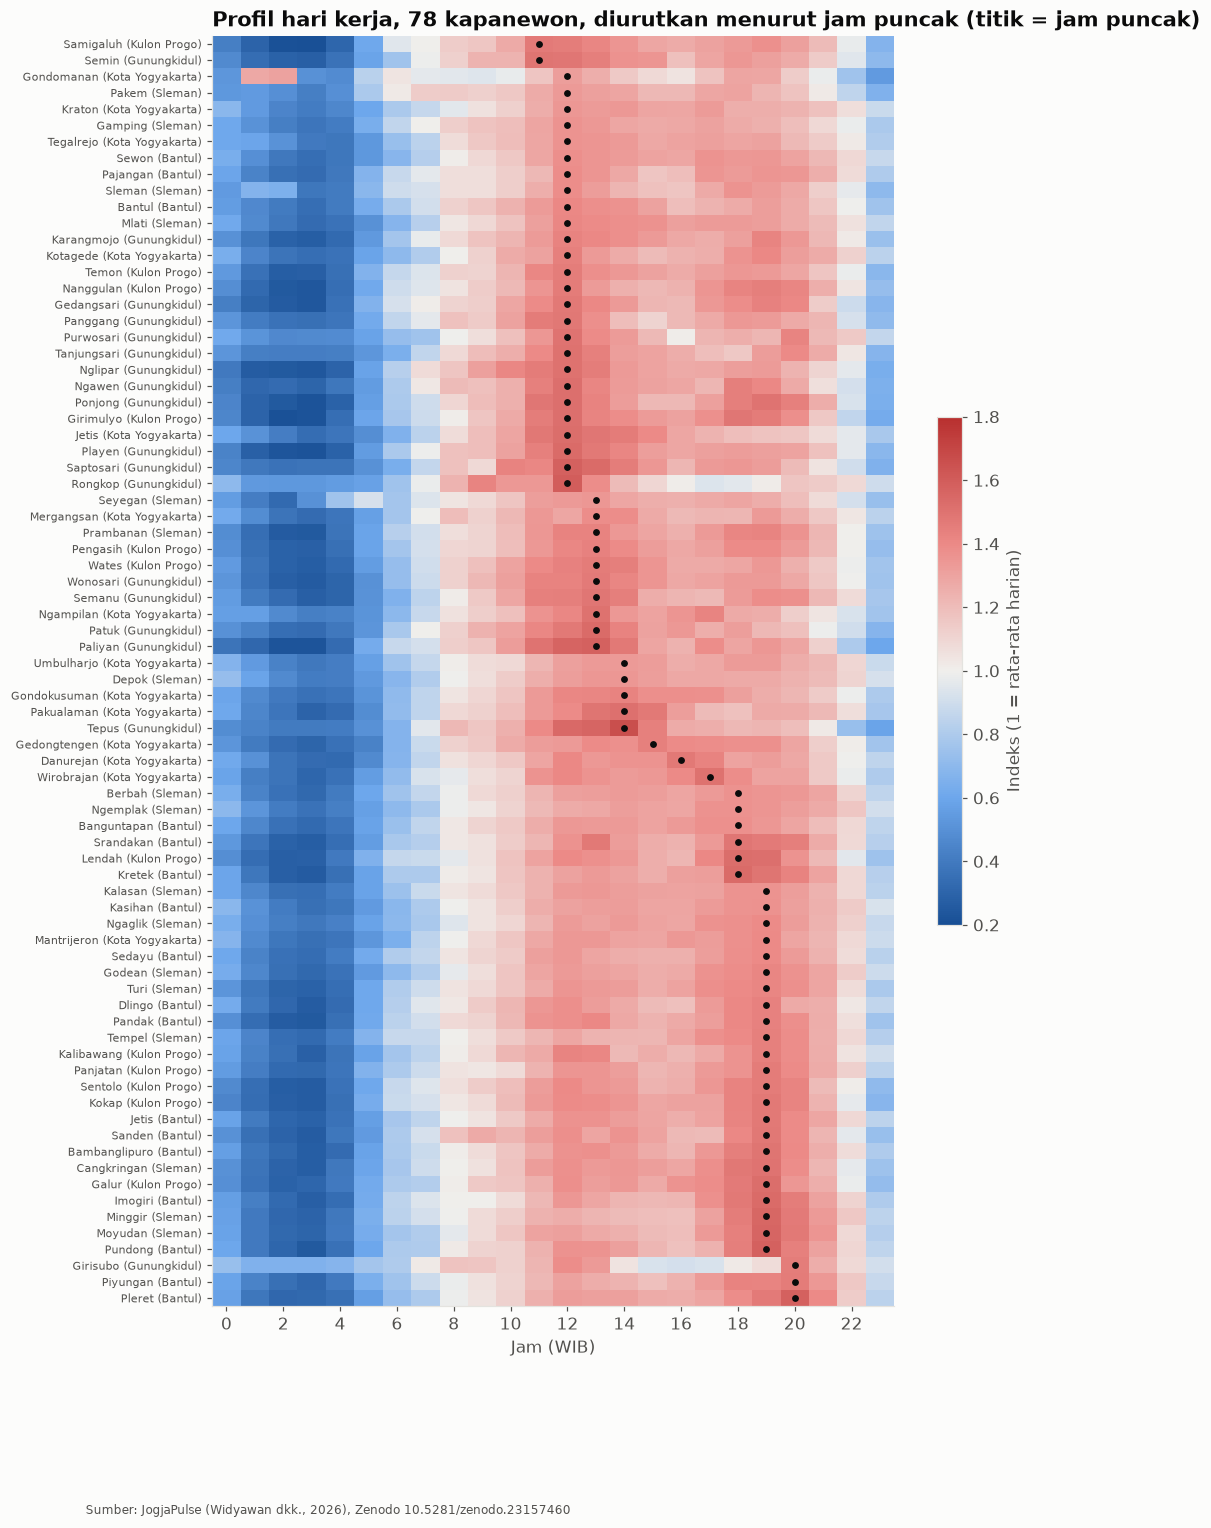

In [7]:
puncak = prof_kerja.idxmax(axis=1).rename("jam_puncak")
info = lookup.set_index("kapanewon_code").join([puncak, terisi])
urut = info.assign(nilai_puncak=prof_kerja.max(axis=1)).sort_values(["jam_puncak", "nilai_puncak"]).index

fig, ax = plt.subplots(figsize=(10, 15))
im = ax.imshow(prof_kerja.loc[urut], aspect="auto", cmap=style.DIVERGING, vmin=0.2, vmax=1.8)
ax.set_yticks(range(len(urut)))
ax.set_yticklabels(
    [f"{info.loc[c, 'kapanewon'].title()} ({style.KAB_LABELS[info.loc[c, 'kab_kota']]})" for c in urut],
    fontsize=7,
)
ax.scatter(info.loc[urut, "jam_puncak"], range(len(urut)), marker="o", s=12, color=style.TEXT_PRIMARY)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Jam (WIB)")
ax.set_title("Profil hari kerja, 78 kapanewon, diurutkan menurut jam puncak (titik = jam puncak)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.4, label="Indeks (1 = rata-rata harian)")
style.add_source(fig)
style.save(fig, "A2_heatmap_jam_puncak_utuh")
plt.show()

In [8]:
def kelompok_puncak(jam):
    if 10 <= jam <= 15:
        return "Siang (10-15)"
    if 17 <= jam <= 21:
        return "Petang (17-21)"
    return "Lainnya"

info["kelompok_puncak"] = info["jam_puncak"].map(kelompok_puncak)
pd.crosstab(info["kab_kota"], info["kelompok_puncak"]).loc[style.KAB_ORDER]

kelompok_puncak,Lainnya,Petang (17-21),Siang (10-15)
kab_kota,,,
YOGYAKARTA,1,2,11
SLEMAN,0,10,7
BANTUL,0,14,3
KULON PROGO,0,6,6
GUNUNGKIDUL,0,1,17


Versi ringkas heatmap: 8 kapanewon dengan puncak siang paling tegas dan 8 dengan puncak petang paling tegas. Kapanewon bertanda `*` (data kurang andal) tidak diikutkan.

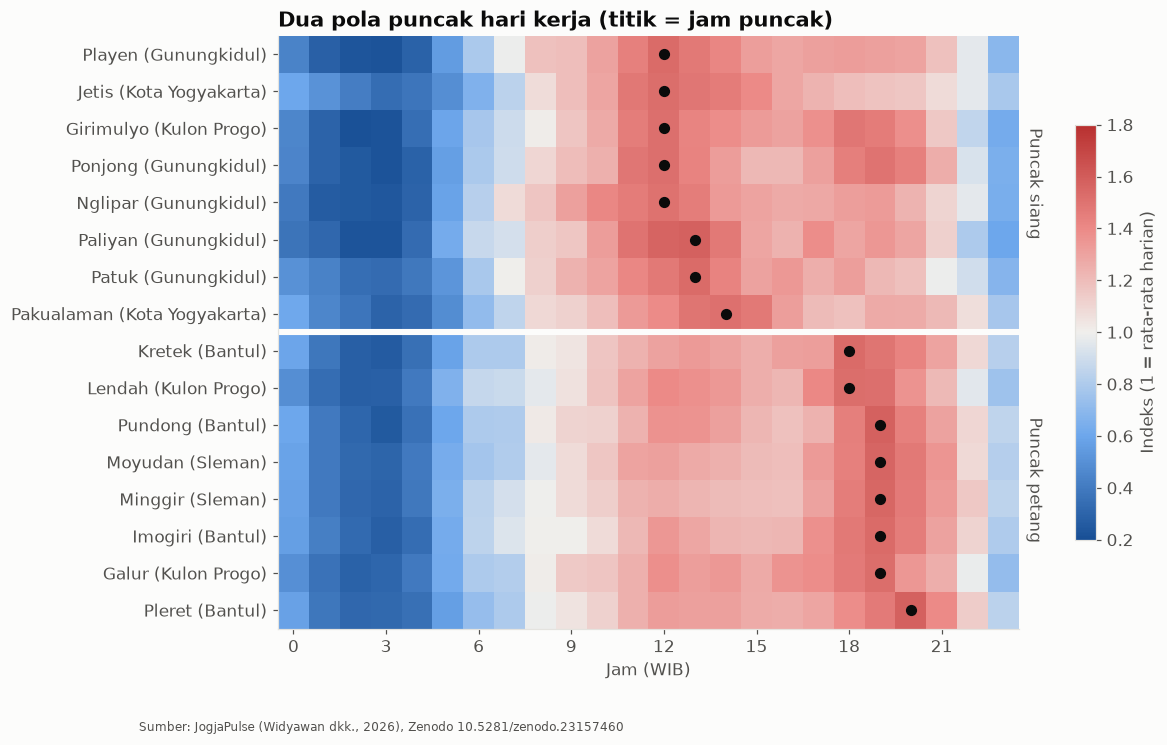

In [9]:
N_PER_KELOMPOK = 8
kuat = info.assign(nilai_puncak=prof_kerja.max(axis=1))
kuat = kuat[kuat["prop_jam_terisi"] <= 0.20]
pilih_kelompok = {
    k: kuat[kuat["kelompok_puncak"] == k].nlargest(N_PER_KELOMPOK, "nilai_puncak").sort_values("jam_puncak").index
    for k in ["Siang (10-15)", "Petang (17-21)"]
}
urut_ringkas = pilih_kelompok["Siang (10-15)"].append(pilih_kelompok["Petang (17-21)"])

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(prof_kerja.loc[urut_ringkas], aspect="auto", cmap=style.DIVERGING, vmin=0.2, vmax=1.8)
ax.set_yticks(range(len(urut_ringkas)))
ax.set_yticklabels(
    [f"{info.loc[c, 'kapanewon'].title()} ({style.KAB_LABELS[info.loc[c, 'kab_kota']]})" for c in urut_ringkas],
    fontsize=11,
)
ax.scatter(info.loc[urut_ringkas, "jam_puncak"], range(len(urut_ringkas)), marker="o", s=40, color=style.TEXT_PRIMARY)
ax.axhline(N_PER_KELOMPOK - 0.5, color=style.SURFACE, linewidth=4)
for y, teks in [(N_PER_KELOMPOK / 2 - 0.5, "Puncak siang"), (N_PER_KELOMPOK * 1.5 - 0.5, "Puncak petang")]:
    ax.annotate(teks, xy=(1.01, y), xycoords=("axes fraction", "data"), rotation=-90,
                va="center", ha="left", fontsize=11, color=style.TEXT_SECONDARY)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Jam (WIB)")
ax.set_title("Dua pola puncak hari kerja (titik = jam puncak)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, pad=0.06, label="Indeks (1 = rata-rata harian)")
style.add_source(fig)
style.save(fig, "A2_heatmap_jam_puncak_ringkas")
plt.show()

## 3. Hari kerja vs Sabtu vs Minggu

Ukuran: rata-rata indeks jam siang (08-17). Tiap hari menjadi satu pengamatan, jadi yang dibandingkan adalah 61 hari kerja dengan 11 Sabtu dan 13 Minggu. Selisih disebut kuat kalau interval kepercayaan 95% tidak melewati nol.

In [10]:
siang_diy = tabel[tabel["hour"].isin(JAM_SIANG)].groupby(["date", "tipe_hari"])["indeks"].mean().reset_index()
siang_kab = tabel_kab[tabel_kab["hour"].isin(JAM_SIANG)].groupby(["kab_kota", "date", "tipe_hari"])["indeks"].mean().reset_index()

baris = []
wilayah = [("Seluruh DIY", siang_diy)] + [(style.KAB_LABELS[k], siang_kab[siang_kab["kab_kota"] == k]) for k in style.KAB_ORDER]
for nama, data in wilayah:
    kerja = data.loc[data["tipe_hari"] == "Hari kerja", "indeks"]
    for t in ["Sabtu", "Minggu"]:
        baris.append({"wilayah": nama, "dibanding": t, **ci_selisih(kerja, data.loc[data["tipe_hari"] == t, "indeks"])})
uji_akhir_pekan = pd.DataFrame(baris)
uji_akhir_pekan

,wilayah,dibanding,selisih,ci_bawah,ci_atas,n_hari,kuat
0,Seluruh DIY,Sabtu,-0.027,-0.050,-0.006,11,True
1,Seluruh DIY,Minggu,-0.025,-0.057,0.001,13,False
2,Kota Yogyakarta,Sabtu,-0.048,-0.092,-0.005,11,True
3,Kota Yogyakarta,Minggu,-0.070,-0.112,-0.032,13,True
4,Sleman,Sabtu,-0.011,-0.035,0.011,11,False
5,Sleman,Minggu,-0.026,-0.075,0.012,13,False
6,Bantul,Sabtu,-0.012,-0.035,0.010,11,False
7,Bantul,Minggu,-0.002,-0.033,0.025,13,False
8,Kulon Progo,Sabtu,-0.022,-0.050,0.003,11,False
9,Kulon Progo,Minggu,-0.013,-0.044,0.013,13,False


Grafik di bawah menunjukkan selisih hari Minggu per kapanewon. Karena hanya ada 13 hari Minggu, selisih per kapanewon ini kami perlakukan sebagai pengamatan dan tidak kami uji.

In [11]:
siang = {t: prof.xs(t, level="tipe_hari")[JAM_SIANG].mean(axis=1) for t in TIPE_HARI}
selisih = (siang["Minggu"] - siang["Hari kerja"]).rename("selisih_minggu").to_frame().join(info)
selisih.groupby("kab_kota")["selisih_minggu"].mean().loc[style.KAB_ORDER].round(3)

kab_kota
YOGYAKARTA    -0.069
SLEMAN        -0.025
BANTUL        -0.001
KULON PROGO   -0.013
GUNUNGKIDUL   -0.020
Name: selisih_minggu, dtype: float64

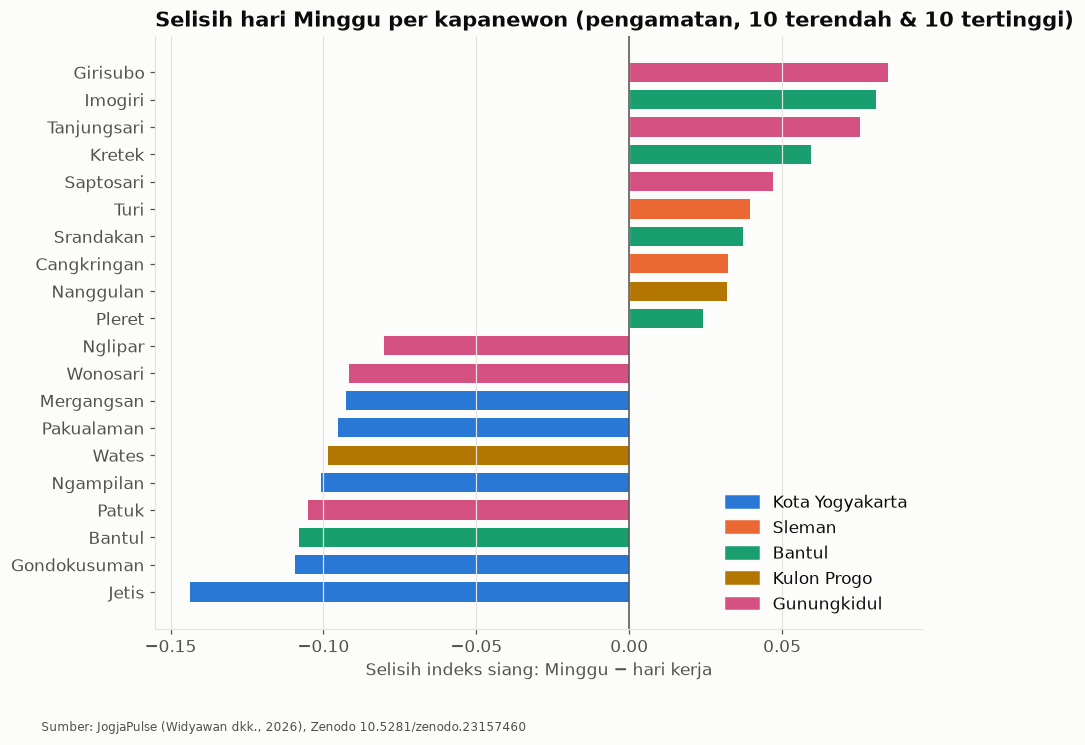

In [12]:
ujung = pd.concat([selisih.nsmallest(10, "selisih_minggu"), selisih.nlargest(10, "selisih_minggu").iloc[::-1]])
ujung = ujung.sort_values("selisih_minggu")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    [k.title() for k in ujung["kapanewon"]], ujung["selisih_minggu"],
    color=[style.KAB_COLORS[k] for k in ujung["kab_kota"]], height=0.7,
)
ax.axvline(0, color=style.TEXT_SECONDARY, linewidth=1)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Selisih indeks siang: Minggu − hari kerja")
ax.set_title("Selisih hari Minggu per kapanewon (pengamatan, 10 terendah & 10 tertinggi)")
present = [k for k in style.KAB_ORDER if k in set(ujung["kab_kota"])]
ax.legend(
    [plt.Rectangle((0, 0), 1, 1, color=style.KAB_COLORS[k]) for k in present],
    [style.KAB_LABELS[k] for k in present], loc="lower right",
)
style.add_source(fig)
style.save(fig, "A3_efek_hari_minggu")
plt.show()

## 4. Hari libur

Hari libur yang jatuh di hari kerja dibandingkan dengan hari kerja biasa dalam jarak ±7 hari dari tanggal itu. Pembanding yang dekat membuat perbandingan tetap adil walaupun sampel data berubah dari bulan ke bulan. Analisis ini memakai seluruh periode, karena 3 dari 5 hari libur itu ada di Maret-April.

Natal (25 Des) jatuh di hari Sabtu, dan Tahun Baru (1 Jan) di hari Sabtu sekaligus tanggal anomali data. Keduanya tidak dipakai di perbandingan ini, karena efek libur akan tercampur dengan efek akhir pekan.

In [13]:
tabel_penuh, terisi_penuh = hitung_indeks(hourly, *PERIODE_PENUH)
print("Proporsi jam terisi, seluruh periode:")
print(terisi_penuh.to_frame().join(lookup.set_index("kapanewon_code")).groupby("kab_kota")["prop_jam_terisi"].mean().loc[style.KAB_ORDER].round(3).to_dict())

libur_kerja = HARI_LIBUR[(HARI_LIBUR["tanggal"].dt.day_of_week < 5) & ~HARI_LIBUR["tanggal"].isin(ANOMALI_DATA)]
hari_kerja_penuh = tabel_penuh.loc[tabel_penuh["tipe_hari"] == "Hari kerja", "date"].drop_duplicates()


def profil_tanggal(tabel, tanggal):
    """Rata-rata indeks per kapanewon × jam untuk sekumpulan tanggal."""
    return tabel[tabel["date"].isin(tanggal)].groupby(["kapanewon_code", "hour"])["indeks"].mean().unstack("hour")


per_libur, prof_libur, prof_pembanding, semua_pembanding = [], [], [], set()
for row in libur_kerja.itertuples():
    pembanding = hari_kerja_penuh[(hari_kerja_penuh - row.tanggal).abs() <= pd.Timedelta(days=JENDELA_PEMBANDING_HARI)]
    p_libur = profil_tanggal(tabel_penuh, [row.tanggal])
    p_pemb = profil_tanggal(tabel_penuh, pembanding)
    prof_libur.append(p_libur)
    prof_pembanding.append(p_pemb)
    semua_pembanding.update(pembanding)
    selisih_siang = p_libur[JAM_SIANG].mean(axis=1) - p_pemb[JAM_SIANG].mean(axis=1)
    per_libur.append({
        "tanggal": row.tanggal.date(),
        "hari_libur": row.nama,
        "hari": prep.WEEKDAY_NAMES_ID[row.tanggal.weekday()],
        "n_hari_pembanding": len(pembanding),
        "selisih_indeks_siang": round(selisih_siang.mean(), 3),
    })
pd.DataFrame(per_libur)

Proporsi jam terisi, seluruh periode:
{'YOGYAKARTA': 0.107, 'SLEMAN': 0.056, 'BANTUL': 0.127, 'KULON PROGO': 0.205, 'GUNUNGKIDUL': 0.405}


,tanggal,hari_libur,hari,n_hari_pembanding,selisih_indeks_siang
0,2022-02-01,Imlek,Selasa,10,-0.077
1,2022-02-28,Isra Mikraj,Senin,9,-0.045
2,2022-03-03,Nyepi,Kamis,8,0.017
3,2022-04-15,Wafat Isa Almasih,Jumat,10,-0.062
4,2022-04-29,Cuti bersama Idulfitri,Jumat,5,-0.011


In [14]:
rata_libur = sum(prof_libur) / len(prof_libur)
rata_pembanding = sum(prof_pembanding) / len(prof_pembanding)
siang_libur = rata_libur[JAM_SIANG].mean(axis=1)
siang_pembanding = rata_pembanding[JAM_SIANG].mean(axis=1)
per_hari = pd.DataFrame(per_libur)["selisih_indeks_siang"].to_numpy()
boot = np.random.default_rng(0).choice(per_hari, (N_BOOT, len(per_hari))).mean(axis=1)
print(f"Rata-rata selisih {len(per_hari)} hari libur: {per_hari.mean():+.3f}, "
      f"CI95 [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]; "
      f"{(per_hari < 0).sum()} dari {len(per_hari)} hari libur lebih sepi dari pembandingnya")

selisih_libur = (siang_libur - siang_pembanding).rename("selisih_libur").to_frame().join(lookup.set_index("kapanewon_code"))
selisih_libur.groupby("kab_kota")["selisih_libur"].mean().loc[style.KAB_ORDER].round(3)

Rata-rata selisih 5 hari libur: -0.036, CI95 [-0.065, -0.007]; 4 dari 5 hari libur lebih sepi dari pembandingnya


kab_kota
YOGYAKARTA    -0.088
SLEMAN        -0.025
BANTUL        -0.024
KULON PROGO   -0.041
GUNUNGKIDUL   -0.011
Name: selisih_libur, dtype: float64

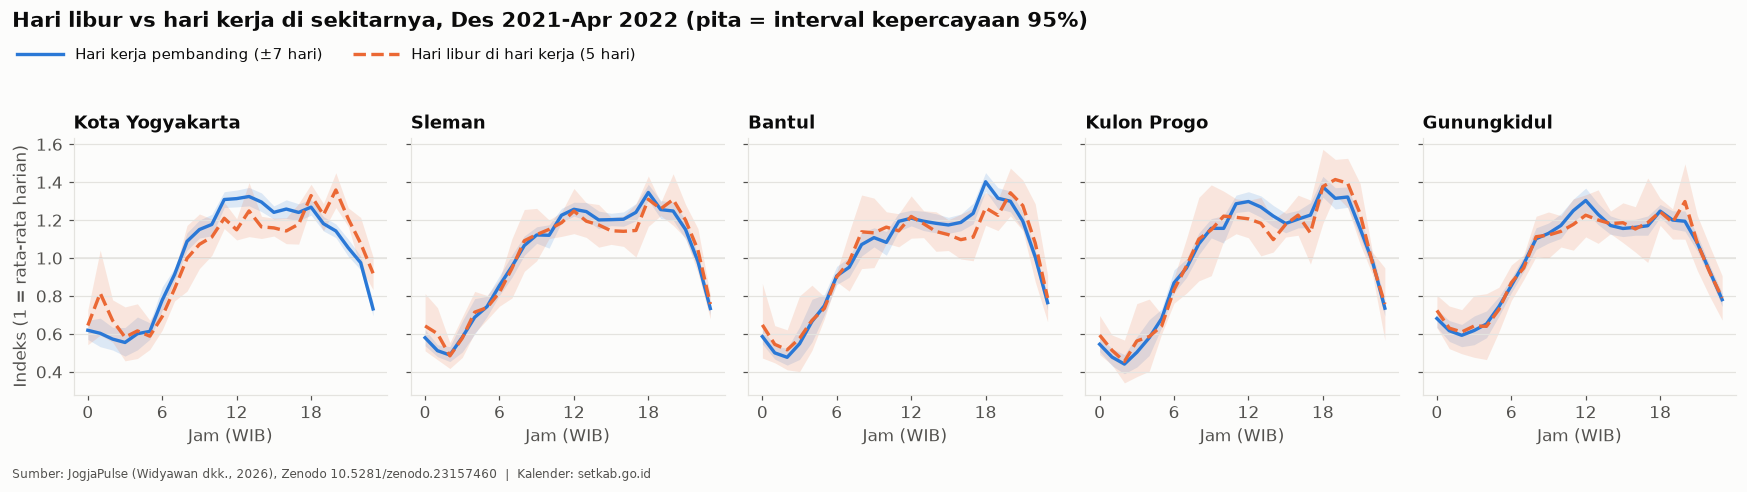

In [15]:
tabel_penuh_kab = tabel_penuh.assign(kab_kota=tabel_penuh["kapanewon_code"].map(KAB_MAP))
garis = [
    (sorted(semua_pembanding), style.CATEGORICAL[0], "-", "Hari kerja pembanding (±7 hari)"),
    (libur_kerja["tanggal"], style.CATEGORICAL[1], "--", f"Hari libur di hari kerja ({len(libur_kerja)} hari)"),
]

fig, axes = plt.subplots(1, 5, figsize=(16, 4.2), sharey=True)
for ax, kab in zip(axes, style.KAB_ORDER):
    for tanggal, warna, gaya, label in garis:
        rata, bawah, atas = pita_bootstrap(harian_per_jam(tabel_penuh_kab[tabel_penuh_kab["kab_kota"] == kab], tanggal))
        ax.fill_between(range(24), bawah, atas, color=warna, alpha=0.15, linewidth=0)
        ax.plot(range(24), rata, color=warna, linestyle=gaya, linewidth=2.2, label=label)
    ax.axhline(1, color=style.GRID, linewidth=1, zorder=0)
    ax.set_title(style.KAB_LABELS[kab], fontsize=12)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Jam (WIB)")
axes[0].set_ylabel("Indeks (1 = rata-rata harian)")
fig.suptitle("Hari libur vs hari kerja di sekitarnya, Des 2021-Apr 2022 (pita = interval kepercayaan 95%)", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.93), ncol=2, fontsize=10, handlelength=3)
fig.tight_layout(rect=(0, 0, 1, 0.88))
style.add_source(fig, style.SOURCE_NOTE + "  |  Kalender: setkab.go.id")
style.save(fig, "A5_hari_libur")
plt.show()

## 5. Rasio siang/malam: pusat kegiatan vs kawasan hunian

Rasio = rata-rata indeks 08-17 ÷ rata-rata indeks 00-05 (hari kerja). Rasio tinggi = jauh lebih ramai siang daripada malam.

> Catatan: kehadiran dihitung dari perangkat yang mengirim ping. Ponsel jarang dipakai di malam hari, jadi kehadiran malam di semua tempat lebih rendah dari jumlah orang sebenarnya. Rasio ini hanya bisa dipakai untuk membandingkan kapanewon satu sama lain, tidak untuk menghitung penduduk siang dan malam.

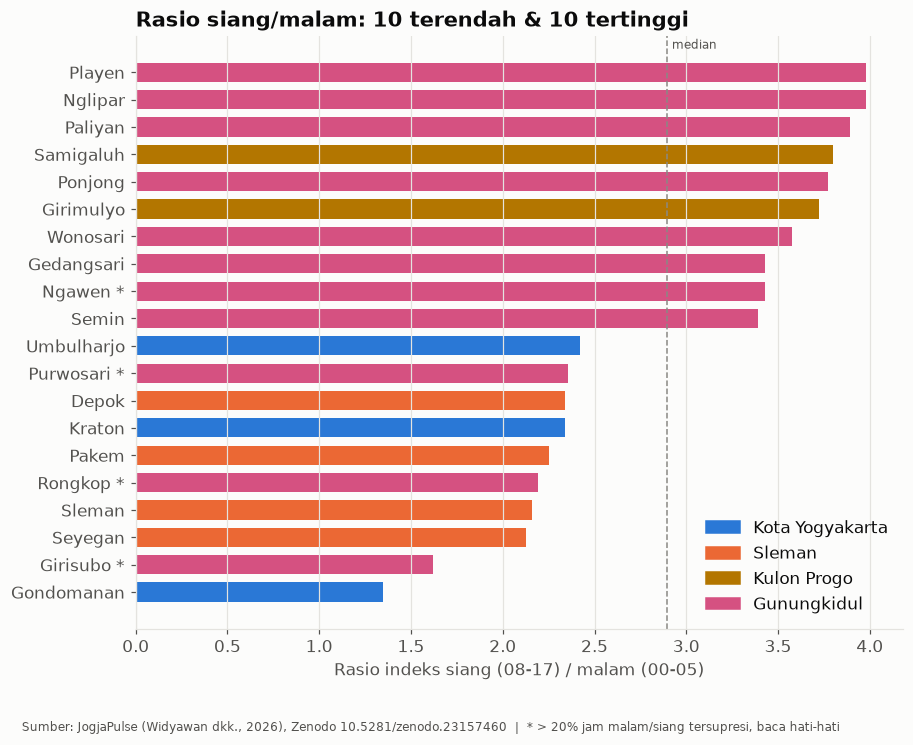

In [16]:
rasio = rasio_siang_malam(prof_kerja).to_frame().join(info)
rasio["ditandai"] = rasio["prop_jam_terisi"] > 0.20
pilih = pd.concat([rasio.nsmallest(10, "rasio_siang_malam"), rasio.nlargest(10, "rasio_siang_malam")]).sort_values("rasio_siang_malam")

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(
    [k.title() + (" *" if t else "") for k, t in zip(pilih["kapanewon"], pilih["ditandai"])],
    pilih["rasio_siang_malam"],
    color=[style.KAB_COLORS[k] for k in pilih["kab_kota"]], height=0.7,
)
ax.axvline(rasio["rasio_siang_malam"].median(), color=style.EVENT_LINE, linestyle="--", linewidth=1)
ax.annotate("median", (rasio["rasio_siang_malam"].median(), 1.0), xycoords=("data", "axes fraction"),
            xytext=(3, -2), textcoords="offset points", fontsize=8, color=style.TEXT_SECONDARY, va="top")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Rasio indeks siang (08-17) / malam (00-05)")
ax.set_title("Rasio siang/malam: 10 terendah & 10 tertinggi")
present = [k for k in style.KAB_ORDER if k in set(pilih["kab_kota"])]
ax.legend(
    [plt.Rectangle((0, 0), 1, 1, color=style.KAB_COLORS[k]) for k in present],
    [style.KAB_LABELS[k] for k in present], loc="lower right",
)
style.add_source(fig, style.SOURCE_NOTE + "  |  * > 20% jam malam/siang tersupresi, baca hati-hati")
style.save(fig, "A4_rasio_siang_malam")
plt.show()

### Catatan khusus: Gondomanan

Gondomanan punya rasio terendah karena lonjakan kehadiran pada jam 01-02 dini hari. Sel di bawah mengeceknya per bulan. Kalau lonjakan baru muncul setelah sampel data berubah (16 Feb), kemungkinan besar penyebabnya perubahan komposisi sampel.

In [17]:
g = hourly[hourly.kapanewon == "GONDOMANAN"].assign(month=lambda d: d.date.dt.strftime("%Y-%m"))
harian = g.groupby("date")["n_maids"].transform("mean")
g = g.assign(indeks=g["n_maids"] / harian)
g[g.hour.isin([1, 2])].groupby("month")["indeks"].median().round(2).rename("median indeks jam 01-02")

month
2021-12    0.68
2022-01    0.66
2022-02    1.05
2022-03    4.53
2022-04    0.77
Name: median indeks jam 01-02, dtype: float64

## 6. Uji sensitivitas

Apakah hasil berubah kalau (a) periode diperpanjang sampai April, (b) isian jam tersupresi diganti 0 atau 4,9, atau (c) jam bolong tidak ditutup? Untuk rasio siang/malam dipakai korelasi Spearman antar peringkat 78 kapanewon (makin dekat 1, makin stabil). Untuk akhir pekan dilaporkan selisih indeks siang seluruh DIY beserta interval kepercayaan 95%.

In [18]:
def ringkas_varian(start, end, isian, tutup_jam_bolong):
    t, _ = hitung_indeks(hourly, start, end, isian, tutup_jam_bolong)
    p_kerja = profil(t).xs("Hari kerja", level="tipe_hari")
    harian = t[t["hour"].isin(JAM_SIANG)].groupby(["date", "tipe_hari"])["indeks"].mean().reset_index()
    kerja = harian.loc[harian["tipe_hari"] == "Hari kerja", "indeks"]
    akhir_pekan = {
        hari: ci_selisih(kerja, harian.loc[harian["tipe_hari"] == hari, "indeks"]) for hari in ["Sabtu", "Minggu"]
    }
    return rasio_siang_malam(p_kerja), p_kerja.idxmax(axis=1).map(kelompok_puncak), akhir_pekan


def teks_ci(h):
    return f"{h['selisih']:+.3f} [{h['ci_bawah']:+.3f}, {h['ci_atas']:+.3f}]"


utama = rasio["rasio_siang_malam"]
varian = {
    "Utama (Des-Feb, isian 2,5, jam bolong ditutup)": (*PERIODE_UTAMA, 2.5, True),
    "Jam bolong tidak ditutup": (*PERIODE_UTAMA, 2.5, False),
    "Periode Des-Apr": (*PERIODE_PENUH, 2.5, True),
    "Isian 0": (*PERIODE_UTAMA, 0.0, True),
    "Isian 4,9": (*PERIODE_UTAMA, 4.9, True),
}
hasil = []
for nama, arg in varian.items():
    r, p, ap = ringkas_varian(*arg)
    hasil.append({
        "varian": nama,
        "spearman_rasio": round(stats.spearmanr(utama, r.loc[utama.index]).statistic, 2),
        "kelompok_puncak_sama_%": round(100 * (p.loc[utama.index] == info.loc[utama.index, "kelompok_puncak"]).mean(), 1),
        "selisih_sabtu [CI95]": teks_ci(ap["Sabtu"]),
        "selisih_minggu [CI95]": teks_ci(ap["Minggu"]),
    })
pd.DataFrame(hasil)

,varian,spearman_rasio,kelompok_puncak_sama_%,selisih_sabtu [CI95],selisih_minggu [CI95]
0,"Utama (Des-Feb, isian 2,5, jam bolong ditutup)",1.00,100.0,"-0.027 [-0.050, -0.006]","-0.025 [-0.057, +0.001]"
1,Jam bolong tidak ditutup,1.00,100.0,"-0.036 [-0.067, -0.009]","-0.023 [-0.055, +0.003]"
2,Periode Des-Apr,0.53,83.3,"-0.036 [-0.070, -0.003]","-0.037 [-0.083, +0.004]"
3,Isian 0,0.66,98.7,"-0.033 [-0.056, -0.010]","-0.026 [-0.053, -0.003]"
4,"Isian 4,9",0.73,100.0,"-0.025 [-0.050, -0.002]","-0.024 [-0.058, +0.005]"


## Simpan hasil

Tabel ringkasan per kapanewon disimpan ke `data/processed/` (tidak di-commit) supaya bisa dipakai anggota lain, misalnya sebagai fitur klasterisasi B.

In [19]:
ringkasan = (
    info.join(rasio["rasio_siang_malam"])
    .join(selisih["selisih_minggu"])
    .join(selisih_libur["selisih_libur"])
    .join(prof_kerja.add_prefix("idx_kerja_h"))
    .reset_index()
)
io.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out = io.PROCESSED_DIR / "A_ritme_kapanewon.csv"
ringkasan.to_csv(out, index=False)
print("Disimpan:", out.relative_to(io.ROOT), ringkasan.shape)

Disimpan: data/processed/A_ritme_kapanewon.csv (78, 34)


## Temuan

Hari kerja, Sabtu, dan Minggu memakai Desember 2021 sampai Februari 2022: 61 hari kerja, 11 Sabtu, dan 13 Minggu, tanpa hari libur, tanpa tanggal anomali data, dan dengan 4 jam bolong ditutup. Perbandingan hari libur memakai seluruh periode.

### 1. Semua wilayah paling sepi pukul 03.00, tapi jam puncaknya terbelah dua

- Titik terendah semua kabupaten/kota ada di pukul 03.00, dengan indeks 0,27 sampai 0,36 (sekitar sepertiga rata-rata harian). Kehadiran mulai naik tajam pukul 05.00.
- Kota Yogyakarta (11 dari 14 kapanewon) dan Gunungkidul (17 dari 18) memuncak siang hari, antara pukul 10 dan 15.
- Bantul (14 dari 17) dan Sleman (10 dari 17) memuncak petang, kebanyakan pukul 19.00. Kulon Progo terbagi rata, 6 dan 6.
- Dugaan kami: puncak petang menandai kawasan hunian di pinggiran kota, tempat orang pulang lalu memakai ponsel di rumah. Puncak siang menandai pusat kegiatan. Puncak siang di Gunungkidul bisa juga dipengaruhi pasar, pertanian, atau supresi jam malam. Hasil klaster B bisa dipakai untuk mengujinya.
- Pembagian siang dan petang ini stabil. Di semua uji sensitivitas, 83 sampai 100% kapanewon tetap di kelompok yang sama.

### 2. Sabtu sedikit lebih sepi di siang hari; hari Minggu hanya jelas di Kota Yogyakarta

Ketidakpastian dihitung per hari (11 Sabtu, 13 Minggu, 61 hari kerja), dan selisih disebut kuat hanya kalau interval kepercayaan 95% tidak melewati nol.

- Di seluruh DIY, Sabtu sedikit lebih sepi di siang hari daripada hari kerja: −0,027 [−0,050, −0,006], sekitar 3% dari rata-rata harian. Hasil ini bertahan di kelima varian uji sensitivitas.
- Hari Minggu di seluruh DIY tidak berbeda nyata dari hari kerja: −0,025 [−0,057, +0,001].
- Kota Yogyakarta adalah satu-satunya wilayah yang jelas lebih sepi di hari Minggu: −0,070 [−0,112, −0,032]. Kota Yogyakarta (−0,048) dan Gunungkidul (−0,044) juga jelas lebih sepi di hari Sabtu. Di Sleman, Bantul, dan Kulon Progo, selisih akhir pekan tidak kuat.
- Per kapanewon, Jetis (Kota), Gondokusuman, dan Ngampilan termasuk yang paling sepi di hari Minggu, sedangkan Girisubo, Tanjungsari, Kretek (Parangtritis), dan Imogiri justru lebih ramai. Dengan 13 hari Minggu, pola per kapanewon ini masih berupa pengamatan.

### 3. Hari libur cenderung lebih sepi, tapi buktinya terbatas

- Empat dari lima hari libur yang jatuh di hari kerja lebih sepi di siang hari daripada hari kerja dalam jarak ±7 hari: Imlek (−0,077), Wafat Isa Almasih (−0,062), Isra Mikraj (−0,045), dan cuti bersama 29 April (−0,011). Nyepi justru sedikit lebih ramai (+0,017).
- Rata-ratanya −0,036 [−0,065, −0,007]. Interval ini dihitung dari 5 hari saja, jadi hasilnya mudah berubah kalau ada satu hari libur tambahan.
- Seperti hari Minggu, penurunan terbesar ada di Kota Yogyakarta (rata-rata −0,088). Kretek dan Girisubo di pesisir justru lebih ramai.
- 3 dari 5 hari libur itu ada di Maret-April, saat jam yang tersupresi jauh lebih banyak (di Gunungkidul 41% jam). Karena itu hasil ini kami sebut kecenderungan.

### 4. Rasio siang/malam memisahkan desa di selatan dan barat dari wilayah lain

- Rasio tertinggi, artinya paling sepi di malam hari, didominasi kapanewon pedesaan di Gunungkidul dan Kulon Progo: Playen, Nglipar, Paliyan, Samigaluh, Ponjong, dan Girimulyo, dengan rasio sekitar 3,7 sampai 4,0.
- Median rasio per kabupaten: Gunungkidul 3,33, Kulon Progo 3,26, Bantul 2,89, Kota Yogyakarta 2,72, dan Sleman 2,68.
- Rasio terendah lebih campur. Di antara kapanewon dengan data yang andal, ada Sleman bagian utara (Seyegan, Sleman, Pakem) dan kawasan kota atau kampus (Kraton, Depok, Umbulharjo). Data ini tidak cukup untuk menjelaskan kenapa Sleman utara termasuk di sini.
- Peringkat rasio hanya cukup stabil, dengan korelasi Spearman 0,53 sampai 0,73 antar varian metode. Angka ini cukup untuk membedakan kelompok wilayah, tapi terlalu goyah untuk mengurutkan kapanewon satu per satu.

### Catatan Gondomanan

Lonjakan pukul 01.00-02.00 hampir tidak ada di Desember dan Januari (median indeks 0,68). Lonjakan itu muncul di Februari (1,05) dan membesar di Maret (4,53), setelah sampel data berubah pada 16 Februari. Penyebabnya kemungkinan besar komposisi sampel, bukan kehidupan malam. Sebaiknya Gondomanan dikeluarkan dari analisis jam malam.

## Keterbatasan

- Perangkat tidak sama dengan orang. Kehadiran malam di semua tempat lebih rendah dari jumlah penduduk sebenarnya, karena ponsel jarang mengirim lokasi saat tidak dipakai.
- Jam yang tersupresi (kurang dari 5 perangkat) kami isi 2,5. Di Desember-Februari, rata-rata 22% jam di Gunungkidul terisi dengan cara ini, dan di Girisubo 66%. Hasil kapanewon bertanda `*` kurang andal.
- Hari kerja, Sabtu, dan Minggu tidak memakai Maret dan April, karena sampelnya kecil dan komposisinya berubah. Hari libur memakai periode itu, sehingga hasilnya lebih lemah.
- Empat jam pagi yang datanya hampir kosong di seluruh DIY (22 dan 27 Januari, 4 dan 5 Februari) kami tutup memakai ambang yang ditetapkan sejak awal. Penurunan kecil pada Sabtu pukul 09 masih tersisa karena 22 Januari pukul 09 sedikit di atas ambang.
- Tanggal hari libur sudah dicocokkan dengan halaman setkab, tapi notebook ini masih memakai daftar sendiri sampai kalender bersama dari anggota C tersedia.
- Kaitan puncak siang dengan pusat kegiatan dan puncak petang dengan hunian masih dugaan. Pembuktiannya butuh data penggunaan lahan atau hasil klaster B.

## Untuk slide

1. Seluruh DIY paling sepi pukul 03.00. Pusat kota paling ramai siang hari, pinggiran kota paling ramai pukul 19.00.
2. Akhir pekan dan hari libur hanya sedikit lebih sepi. Yang paling jelas: pusat Kota Yogyakarta sepi di hari Minggu.
3. Desa di Gunungkidul dan Kulon Progo paling sepi di malam hari dibanding siangnya.
